In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, VotingClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report


In [ ]:
!pip install kaggle --quiet

import os

os.environ['KAGGLE_CONFIG_DIR'] = '/content'
!kaggle datasets download -d architsharma01/loan-approval-prediction-dataset --unzip

data = pd.read_csv('loan_approval_dataset.csv')
print(data.info())
print(data.head())

Dataset URL: https://www.kaggle.com/datasets/architsharma01/loan-approval-prediction-dataset
License(s): MIT
100% 80.6k/80.6k [00:00<00:00, 569kB/s]
100% 80.6k/80.6k [00:00<00:00, 567kB/s]
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4269 entries, 0 to 4268
Data columns (total 13 columns):
 #   Column                     Non-Null Count  Dtype 
---  ------                     --------------  ----- 
 0   loan_id                    4269 non-null   int64 
 1    no_of_dependents          4269 non-null   int64 
 2    education                 4269 non-null   object
 3    self_employed             4269 non-null   object
 4    income_annum              4269 non-null   int64 
 5    loan_amount               4269 non-null   int64 
 6    loan_term                 4269 non-null   int64 
 7    cibil_score               4269 non-null   int64 
 8    residential_assets_value  4269 non-null   int64 
 9    commercial_assets_value   4269 non-null   int64 
 10   luxury_assets_value       4269 non-nul

In [ ]:
print(data.isnull().sum())

loan_id                      0
 no_of_dependents            0
 education                   0
 self_employed               0
 income_annum                0
 loan_amount                 0
 loan_term                   0
 cibil_score                 0
 residential_assets_value    0
 commercial_assets_value     0
 luxury_assets_value         0
 bank_asset_value            0
 loan_status                 0
dtype: int64


In [ ]:
# Strip leading and trailing spaces from column names
data.columns = data.columns.str.strip()

# Step 1: Handle Missing Values
# Fill missing numeric values with the mean of the respective columns
numeric_columns = data.select_dtypes(include=[np.number]).columns
data[numeric_columns] = data[numeric_columns].fillna(data[numeric_columns].mean())

# For categorical columns, fill missing values with the mode (most frequent value)
categorical_columns = data.select_dtypes(include=['object']).columns
for column in categorical_columns:
    data[column].fillna(data[column].mode()[0], inplace=True)

# Step 2: Encode Categorical Features using One-Hot Encoding
# One-hot encode categorical features (this will create binary columns for each category)
data = pd.get_dummies(data, drop_first=True)

# Remove 'loan_id' column since it's not a feature for prediction
data = data.drop('loan_id', axis=1)

# Check column names to ensure the target column is correctly referenced
print("Columns in the dataset:", data.columns)

# Step 3: Split Data into Features and Target
# Correct the target column name to 'loan_status_ Rejected'
X = data.drop('loan_status_ Rejected', axis=1)  # Drop the target column from features
y = data['loan_status_ Rejected']  # Set the target column

# Display the first few rows of the updated dataset after splitting
print("Features (X):", X.head())
print("Target (y):", y.head())

# Step 4: Split the Data into Training and Testing Sets (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Display the shape of the data
print(f"Training data shape: {X_train.shape}, Testing data shape: {X_test.shape}")

# Step 5: Feature Scaling (Standardizing the data)
# Standardizing features to bring them on the same scale
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)


Columns in the dataset: Index(['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term',
       'cibil_score', 'residential_assets_value', 'commercial_assets_value',
       'luxury_assets_value', 'bank_asset_value', 'education_ Not Graduate',
       'self_employed_ Yes', 'loan_status_ Rejected'],
      dtype='object')
Features (X):    no_of_dependents  income_annum  loan_amount  loan_term  cibil_score  \
0                 2       9600000     29900000         12          778   
1                 0       4100000     12200000          8          417   
2                 3       9100000     29700000         20          506   
3                 3       8200000     30700000          8          467   
4                 5       9800000     24200000         20          382   

   residential_assets_value  commercial_assets_value  luxury_assets_value  \
0                   2400000                 17600000             22700000   
1                   2700000                  2200000         

<ipython-input-4-bef34c0d3e9f>:12: FutureWarning: A value is trying to be set on a copy of a DataFrame or Series through chained assignment using an inplace method.
The behavior will change in pandas 3.0. This inplace method will never work because the intermediate object on which we are setting values always behaves as a copy.

For example, when doing 'df[col].method(value, inplace=True)', try using 'df.method({col: value}, inplace=True)' or df[col] = df[col].method(value) instead, to perform the operation inplace on the original object.


  data[column].fillna(data[column].mode()[0], inplace=True)


In [ ]:
# Scale features using StandardScaler
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [ ]:
# Initialize ExtraTrees and RandomForest models
et_model = ExtraTreesClassifier(n_estimators=100, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Train the models
et_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)

# Print confirmation
print("ExtraTrees and RandomForest models trained successfully!")


ExtraTrees and RandomForest models trained successfully!


In [ ]:
# Make predictions
et_preds = et_model.predict(X_test)
rf_preds = rf_model.predict(X_test)

# Evaluate the models using accuracy score and classification report
print("Extra Trees Accuracy: ", accuracy_score(y_test, et_preds))
print("Extra Trees Classification Report: ")
print(classification_report(y_test, et_preds))

print("Random Forest Accuracy: ", accuracy_score(y_test, rf_preds))
print("Random Forest Classification Report: ")
print(classification_report(y_test, rf_preds))


Extra Trees Accuracy:  0.9578454332552693
Extra Trees Classification Report: 
              precision    recall  f1-score   support

       False       0.97      0.96      0.97       810
        True       0.94      0.95      0.94       471

    accuracy                           0.96      1281
   macro avg       0.95      0.96      0.95      1281
weighted avg       0.96      0.96      0.96      1281

Random Forest Accuracy:  0.9773614363778298
Random Forest Classification Report: 
              precision    recall  f1-score   support

       False       0.97      0.99      0.98       810
        True       0.98      0.96      0.97       471

    accuracy                           0.98      1281
   macro avg       0.98      0.97      0.98      1281
weighted avg       0.98      0.98      0.98      1281



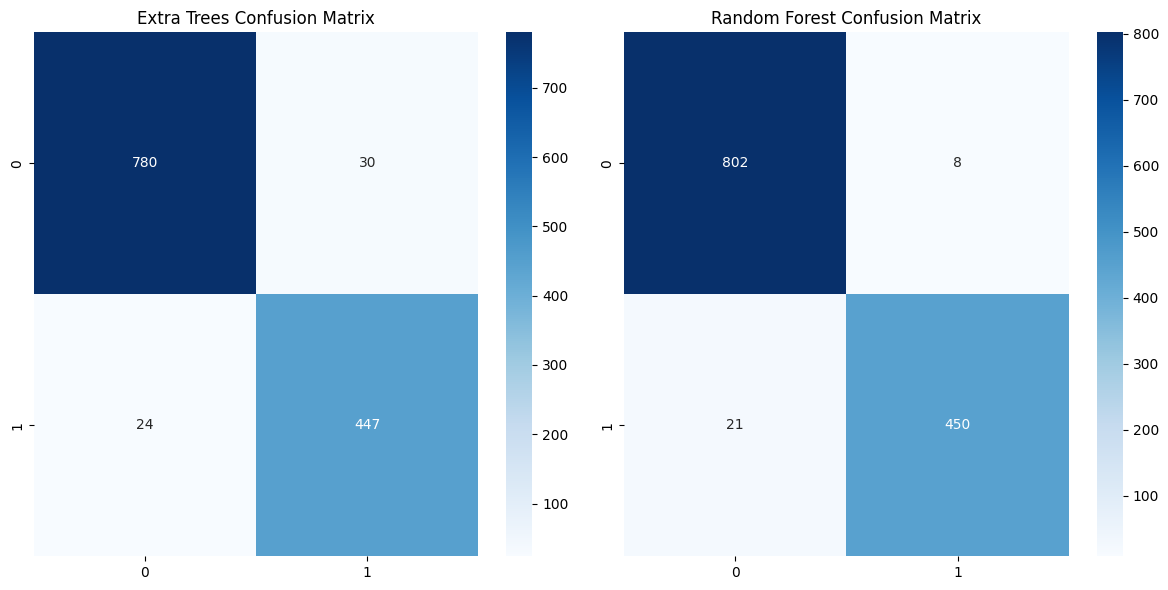

In [ ]:
# Plot Confusion Matrices for both models
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

# Extra Trees Confusion Matrix
sns.heatmap(confusion_matrix(y_test, et_preds), annot=True, fmt='d', cmap='Blues', ax=axes[0])
axes[0].set_title('Extra Trees Confusion Matrix')

# Random Forest Confusion Matrix
sns.heatmap(confusion_matrix(y_test, rf_preds), annot=True, fmt='d', cmap='Blues', ax=axes[1])
axes[1].set_title('Random Forest Confusion Matrix')

plt.tight_layout()
plt.show()


In [ ]:
# Define Voting Classifier that combines ExtraTrees and RandomForest
voting_clf = VotingClassifier(estimators=[('et', et_model), ('rf', rf_model)], voting='hard')

# Train the Voting Classifier
voting_clf.fit(X_train, y_train)

# Make predictions and evaluate
voting_preds = voting_clf.predict(X_test)
print("Voting Classifier Accuracy: ", accuracy_score(y_test, voting_preds))
print("Voting Classifier Classification Report: ")
print(classification_report(y_test, voting_preds))


Voting Classifier Accuracy:  0.9679937548790007
Voting Classifier Classification Report: 
              precision    recall  f1-score   support

       False       0.96      0.99      0.98       810
        True       0.98      0.93      0.96       471

    accuracy                           0.97      1281
   macro avg       0.97      0.96      0.97      1281
weighted avg       0.97      0.97      0.97      1281



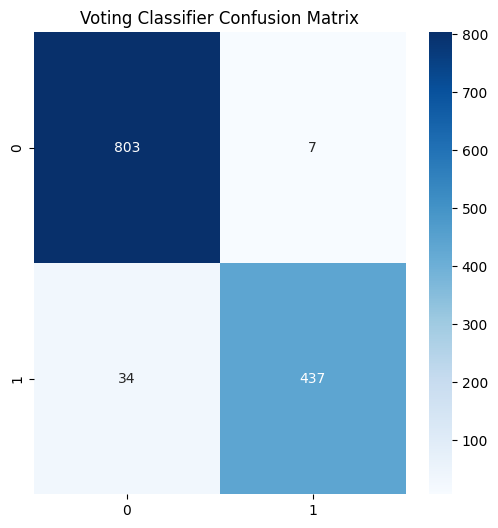

In [ ]:
# Plot Confusion Matrix for Voting Classifier
plt.figure(figsize=(6, 6))
sns.heatmap(confusion_matrix(y_test, voting_preds), annot=True, fmt='d', cmap='Blues')
plt.title('Voting Classifier Confusion Matrix')
plt.show()


In [ ]:
from sklearn.ensemble import VotingClassifier
from sklearn.model_selection import GridSearchCV
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier

# Initialize the classifiers
et_model = ExtraTreesClassifier(n_estimators=100, random_state=42)
rf_model = RandomForestClassifier(n_estimators=100, random_state=42)

# Create the Voting Classifier
voting_model = VotingClassifier(estimators=[('extra_trees', et_model), ('random_forest', rf_model)], voting='hard')

# Hyperparameter tuning for Extra Trees model
param_grid_et = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
}

grid_search_et = GridSearchCV(estimator=et_model, param_grid=param_grid_et, cv=3)
grid_search_et.fit(X_train, y_train)

# Best parameters and score for Extra Trees
print("Best Parameters for Extra Trees: ", grid_search_et.best_params_)
print("Best Score for Extra Trees: ", grid_search_et.best_score_)

# Hyperparameter tuning for Random Forest model
param_grid_rf = {
    'n_estimators': [100, 200],
    'max_depth': [10, 20, None],
    'min_samples_split': [2, 5],
}

grid_search_rf = GridSearchCV(estimator=rf_model, param_grid=param_grid_rf, cv=3)
grid_search_rf.fit(X_train, y_train)

# Best parameters and score for Random Forest
print("Best Parameters for Random Forest: ", grid_search_rf.best_params_)
print("Best Score for Random Forest: ", grid_search_rf.best_score_)

# Hyperparameter tuning for Voting Classifier
param_grid_voting = {
    'voting': ['hard', 'soft'],  # You can choose either hard or soft voting
    'weights': [[1, 1], [2, 1], [1, 2]],  # Weight combinations for each classifier
}

grid_search_voting = GridSearchCV(estimator=voting_model, param_grid=param_grid_voting, cv=3)
grid_search_voting.fit(X_train, y_train)

# Best parameters and score for Voting Classifier
print("Best Parameters for Voting Classifier: ", grid_search_voting.best_params_)
print("Best Score for Voting Classifier: ", grid_search_voting.best_score_)


Best Parameters for Extra Trees:  {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Best Score for Extra Trees:  0.964524765729585
Best Parameters for Random Forest:  {'max_depth': 20, 'min_samples_split': 2, 'n_estimators': 200}
Best Score for Random Forest:  0.9815930388219544
Best Parameters for Voting Classifier:  {'voting': 'hard', 'weights': [1, 2]}
Best Score for Voting Classifier:  0.9782463186077642


In [ ]:
import joblib
et_model.fit(X_train, y_train)
rf_model.fit(X_train, y_train)
voting_model.fit(X_train, y_train)  # Make sure the VotingClassifier is fitted

# Now save the models
joblib.dump(et_model, 'extra_trees_model.pkl')
joblib.dump(rf_model, 'random_forest_model.pkl')
joblib.dump(voting_model, 'voting_classifier_model.pkl')


['voting_classifier_model.pkl']

In [ ]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import StandardScaler

# Load the trained model
et_model = joblib.load('extra_trees_model.pkl')
rf_model = joblib.load('random_forest_model.pkl')
voting_model = joblib.load('voting_classifier_model.pkl')  # Load the Voting Classifier model

# Load the feature columns used during training
feature_columns = ['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term',
                   'cibil_score', 'residential_assets_value', 'commercial_assets_value',
                   'luxury_assets_value', 'bank_asset_value', 'education_ Not Graduate',
                   'self_employed_ Yes']  # Adjust this list to match the trained model features

# Feature Scaling (Standardizing the data)
scaler = StandardScaler()

# Input features
print("Please enter the following details:")

no_of_dependents = float(input("Number of dependents: "))
income_annum = float(input("Annual income: "))
loan_amount = float(input("Loan amount: "))
loan_term = float(input("Loan term: "))
cibil_score = float(input("CIBIL score: "))
residential_assets_value = float(input("Residential assets value: "))
commercial_assets_value = float(input("Commercial assets value: "))
luxury_assets_value = float(input("Luxury assets value: "))
bank_asset_value = float(input("Bank assets value: "))
education_not_graduate = input("Education (Not Graduate) [Yes/No]: ")
self_employed = input("Self-employed [Yes/No]: ")

# Encode categorical features based on user input
education_not_graduate = 1 if education_not_graduate.lower() == 'yes' else 0
self_employed = 1 if self_employed.lower() == 'yes' else 0

# Create a DataFrame for the input values
input_data = pd.DataFrame([[no_of_dependents, income_annum, loan_amount, loan_term,
                            cibil_score, residential_assets_value, commercial_assets_value,
                            luxury_assets_value, bank_asset_value, education_not_graduate, self_employed]],
                          columns=['no_of_dependents', 'income_annum', 'loan_amount', 'loan_term',
                                   'cibil_score', 'residential_assets_value', 'commercial_assets_value',
                                   'luxury_assets_value', 'bank_asset_value', 'education_ Not Graduate',
                                   'self_employed_ Yes'])

# Ensure that the input data has the same number of features as the training data
# This step ensures that the order and presence of the features match the training set
input_data = input_data[feature_columns]

# Feature Scaling (Standardize the input data)
input_data_scaled = scaler.fit_transform(input_data)

# Make predictions using all models
et_prediction = et_model.predict(input_data_scaled)
rf_prediction = rf_model.predict(input_data_scaled)
voting_prediction = voting_model.predict(input_data_scaled)  # Voting Classifier Prediction

# Output the predictions
if et_prediction == 1:
    print("Extra Trees Model Prediction: Loan Approved")
else:
    print("Extra Trees Model Prediction: Loan Rejected")

if rf_prediction == 1:
    print("Random Forest Model Prediction: Loan Approved")
else:
    print("Random Forest Model Prediction: Loan Rejected")

if voting_prediction == 1:
    print("Voting Classifier Prediction: Loan Approved")
else:
    print("Voting Classifier Prediction: Loan Rejected")


Please enter the following details:
Number of dependents: 2
Annual income: 9600000
Loan amount: 29900000
Loan term: 12
CIBIL score: 778
Residential assets value: 2400000
Commercial assets value: 17600000
Luxury assets value: 22700000
Bank assets value: 800000
Education (Not Graduate) [Yes/No]: No
Self-employed [Yes/No]: No
Extra Trees Model Prediction: Loan Rejected
Random Forest Model Prediction: Loan Rejected
Voting Classifier Prediction: Loan Rejected
